# Beam splitter e Mach–Zehnder come gate

### Subject: Optics

Un beam splitter 50/50 è (a meno di fasi) un **Hadamard**. Due splitter
e una fase su un braccio sono un interferometro di Mach–Zehnder: la
stessa algebra di $H\,R_z(\varphi)\,H$ su un qubit. Qui lo si vede
con matrici $2\times 2$ e un fotone, senza copiare circuiti Qiskit.


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

def rk4(f, y0, t):
    y = np.empty((len(t),) + np.shape(y0), dtype=np.asarray(y0).dtype)
    y[0] = y0
    for i in range(len(t) - 1):
        h = t[i + 1] - t[i]
        k1 = f(t[i], y[i])
        k2 = f(t[i] + 0.5 * h, y[i] + 0.5 * h * k1)
        k3 = f(t[i] + 0.5 * h, y[i] + 0.5 * h * k2)
        k4 = f(t[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + (h / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
    return y

print("Setup ready.")


Setup ready.


## 1. Beam splitter = Hadamard

Convenzione simmetrica (come $H$):

$$
U_{\mathrm{BS}}=\frac{1}{\sqrt{2}}\begin{pmatrix}1&1\\1&-1\end{pmatrix}.
$$

Un fotone nel porto $0$ esce in uguale sovrapposizione dei due cammini.
$U_{\mathrm{BS}}$ deve essere unitaria: $U^\dagger U=I$, $\lvert\det U\rvert=1$.


In [2]:
H = np.array([[1.0, 1.0], [1.0, -1.0]], dtype=complex) / np.sqrt(2.0)
assert np.allclose(H.conj().T @ H, np.eye(2))
assert np.isclose(np.abs(np.linalg.det(H)), 1.0)

in0 = np.array([1.0, 0.0], dtype=complex)
out = H @ in0
print("fotone in porto 0 →", np.round(out, 4))
print("|amp|^2 =", np.round(np.abs(out) ** 2, 6))
assert np.allclose(np.abs(out) ** 2, [0.5, 0.5])
print("unitarietà e 50/50: ok")


fotone in porto 0 → [0.7071+0.j 0.7071+0.j]
|amp|^2 = [0.5 0.5]
unitarietà e 50/50: ok


## 2. Mach–Zehnder: $H\,R_z(\varphi)\,H$

Fase sul secondo cammino $R_z(\varphi)=\mathrm{diag}(1,e^{i\varphi})$.
Stato iniziale $\lvert 0\rangle$ (fotone sul primo ingresso):

$$
\lvert\psi_{\mathrm{out}}\rangle = H\,R_z(\varphi)\,H\,\lvert 0\rangle
=\frac{1+e^{i\varphi}}{2}\lvert 0\rangle+\frac{1-e^{i\varphi}}{2}\lvert 1\rangle.
$$

Quindi $P_0=\cos^2(\varphi/2)$, $P_1=\sin^2(\varphi/2)$: **Malus
interferometrico**. $\varphi=0$ è costruttivo sul porto 0; $\varphi=\pi$
scambia i porti.


max |P0 - cos²(φ/2)| = 6.66e-16
φ=0: P0=1.0000  P1=0.0000
φ=π: P0=0.0000  P1=1.0000
φ=π/2: P0=0.5000  P1=0.5000


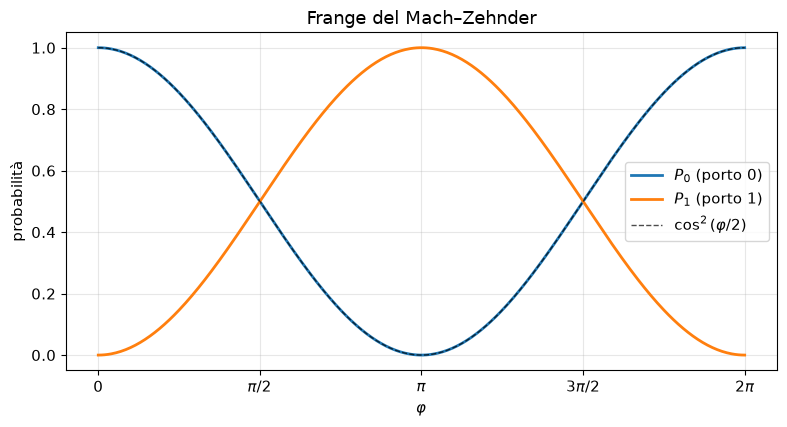

In [3]:
def mach_zehnder(phi, psi0=np.array([1.0, 0.0], dtype=complex)):
    Rz = np.diag([1.0, np.exp(1j * phi)])
    return H @ Rz @ H @ psi0


phis = np.linspace(0.0, 2.0 * np.pi, 401)
P0 = np.array([np.abs(mach_zehnder(phi)[0]) ** 2 for phi in phis])
P1 = 1.0 - P0
theory = np.cos(phis / 2.0) ** 2
err = np.max(np.abs(P0 - theory))
print(f"max |P0 - cos²(φ/2)| = {err:.2e}")
assert err < 1e-12

for phi, name in [(0.0, "φ=0"), (np.pi, "φ=π"), (np.pi / 2, "φ=π/2")]:
    p = np.abs(mach_zehnder(phi)) ** 2
    print(f"{name}: P0={p[0]:.4f}  P1={p[1]:.4f}")

fig, ax = plt.subplots()
ax.plot(phis, P0, lw=2, label=r"$P_0$ (porto 0)")
ax.plot(phis, P1, lw=2, label=r"$P_1$ (porto 1)")
ax.plot(phis, theory, "k--", lw=1.0, alpha=0.7, label=r"$\cos^2(\varphi/2)$")
ax.set_xlabel(r"$\varphi$")
ax.set_ylabel("probabilità")
ax.set_xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
ax.set_xticklabels(["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
ax.legend()
ax.set_title("Frange del Mach–Zehnder")
plt.tight_layout()
plt.show()


## 3. Un fotone, due cammini, stessa unitaria

Se il fotone entra dal porto 1, le frange si scambiano:
$P_0=\sin^2(\varphi/2)$. È l'altra colonna di $H R_z H$. Conservazione:
$P_0+P_1=1$ per ogni $\varphi$ (un fotone, due uscite).


In [4]:
P0_alt = np.array(
    [np.abs(mach_zehnder(phi, np.array([0.0, 1.0], dtype=complex))[0]) ** 2 for phi in phis]
)
assert np.allclose(P0_alt, np.sin(phis / 2.0) ** 2)

U = np.column_stack(
    [mach_zehnder(0.7, np.array([1.0, 0.0], dtype=complex)),
     mach_zehnder(0.7, np.array([0.0, 1.0], dtype=complex))]
)
print("U†U ≈ I:", np.allclose(U.conj().T @ U, np.eye(2)))
print("max |P0+P1-1| =", np.max(np.abs(P0 + P1 - 1.0)))


U†U ≈ I: True
max |P0+P1-1| = 0.0


## Takeaway

Polarizzazione (`01_polarization_as_qubit`) è un qubit nello spazio
di Jones. Qui il qubit è **which-path**. Stessa geometria, due
laboratori.

## Next step
- Lamine $\lambda/4$ e $\lambda/2$ come $R_x$, $R_z$ sulla sfera di Poincaré.
- Visibility $<1$ se si traccia (which-path) un braccio: $\rho$ mista.
